# Hate Speech & Offensive Content Detection in Marathi-English Code-Mixed Text
**Pipeline in one notebook:** load data > EDA > preprocessing > train/val/test split > baseline (TF-IDF + Logistic Regression) > advanced model (fine-tuned MuRIL) > evaluation & comparison > robustness test > error analysis > save models.

**Classes:** `neutral`, `offensive`, `hateful`.
**Files expected in this folder:** `marathi_english_codemixed_devanagari.csv` (main) and optionally `marathi_english_codemixed_dataset.csv` (Roman script, used only for a cross-script test).
To use HASOC or another dataset, change the paths and column names in the config cell: it needs one text column and one label column.

In [1]:
# Run once. The first MuRIL run also downloads the model (~950 MB) from huggingface.co.
%pip install -q pandas numpy scikit-learn matplotlib joblib transformers datasets accelerate torch

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install --upgrade pip

  Using cached pip-26.3-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.3-py3-none-any.whl (2.0 MB)
  Attempting uninstall: pip
    Found existing installation: pip 26.0.1
    Uninstalling pip-26.0.1:
      Successfully uninstalled pip-26.0.1
Note: you may need to restart the kernel to use updated packages.


## 0. Configuration & utilities

In [1]:
import os, re, time, random, unicodedata, inspect, warnings
from collections import Counter
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, precision_recall_fscore_support)
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110)

# ----------------------------- CONFIG -----------------------------
DATA_PATH   = "marathi_english_codemixed_devanagari.csv"   # main dataset
ROMAN_PATH  = "marathi_english_codemixed_dataset.csv"      # optional cross-script test set (set None to skip)
TEXT_COL, LABEL_COL = "text", "label"
LABELS      = ["neutral", "offensive", "hateful"]
SEED        = 42
RUN_TRANSFORMER = True            # set False to run EDA + baseline only (fast debugging)
MODEL_NAME  = "google/muril-base-cased"   # alternatives: "xlm-roberta-base", "l3cube-pune/marathi-bert-v2"
OUT_DIR     = "artifacts"
# ------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
label2id = {l: i for i, l in enumerate(LABELS)}; id2label = {i: l for l, i in label2id.items()}

if RUN_TRANSFORMER:
    import torch
    from torch.utils.data import Dataset
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                              Trainer, EarlyStoppingCallback, DataCollatorWithPadding)
    torch.manual_seed(SEED)
    HAS_GPU = torch.cuda.is_available()
    EPOCHS  = 4 if HAS_GPU else 3
    MAX_LEN = 128 if HAS_GPU else 64
    BATCH   = 16 if HAS_GPU else 8
    print(f"GPU: {HAS_GPU} | epochs={EPOCHS} max_len={MAX_LEN} batch={BATCH}")
    if not HAS_GPU: print("CPU mode: training may take 20-40 min.")

# ---------------------------- preprocessing helpers ----------------------------
def clean_text(t):
    """Normalise text and mask personal information. Keeps Devanagari, English, emojis, hashtags."""
    t = unicodedata.normalize("NFC", str(t))
    t = re.sub(r"[\u200b\u200c\u200d]", "", t)                 # zero-width characters
    t = re.sub(r"https?://\S+|www\.\S+", "<URL>", t)
    t = re.sub(r"\S+@\S+\.\S+", "<EMAIL>", t)
    t = re.sub(r"@\w+", "<USER>", t)
    t = re.sub(r"\b\d{10}\b", "<PHONE>", t)
    t = re.sub(r"(.)\1{3,}", r"\1\1\1", t)                     # sooooo -> sooo
    return re.sub(r"\s+", " ", t).strip()

def dup_key(t):
    """Key for near-duplicate detection: ignores case, punctuation, emoji, hashtags."""
    t = re.sub(r"#\S+", "", t.lower())
    t = re.sub(r"[^\w\s\u0900-\u097F]", "", t)
    return re.sub(r"\s+", " ", t).strip()

def load_csv(path):
    d = pd.read_csv(path).rename(columns={TEXT_COL: "text", LABEL_COL: "label"})
    if "id" not in d.columns: d["id"] = range(len(d))
    d = d.dropna(subset=["text", "label"]).reset_index(drop=True)
    d["label"] = d["label"].str.strip().str.lower()
    return d

# ---------------------------- evaluation helpers ----------------------------
def evaluate(name, y_true, y_pred, train_time=None, ms_per_post=None, n_params=None):
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    row = {"model": name, "accuracy": accuracy_score(y_true, y_pred),
           "macro_F1": f1_score(y_true, y_pred, average="macro"),
           "weighted_F1": f1_score(y_true, y_pred, average="weighted")}
    row.update({f"F1_{l}": v for l, v in zip(LABELS, f1)})
    row.update({"train_time_s": train_time, "ms_per_post": ms_per_post, "params": n_params})
    return row

GPU: False | epochs=3 max_len=64 batch=8
CPU mode: training may take 20-40 min.


In [2]:
if torch.cuda.is_available():
    print("GPU is AVAILABLE!")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())
else:
    print("GPU is NOT available. Running on CPU.")



GPU is NOT available. Running on CPU.


In [4]:
import torch
import time

if torch.cuda.is_available():

    device = torch.device("cuda")

    print("Starting GPU test...")

    # Create large matrices on GPU
    a = torch.randn(5000, 5000, device=device)
    b = torch.randn(5000, 5000, device=device)

    # Perform matrix multiplication
    start_time = time.time()

    c = torch.matmul(a, b)

    torch.cuda.synchronize()

    end_time = time.time()

    print("\nGPU TEST SUCCESSFUL!")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Result shape:", c.shape)
    print("Execution time:", round(end_time - start_time, 4), "seconds")
    print("GPU Memory Allocated:",
          round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

else:
    print("GPU NOT DETECTED!")

GPU NOT DETECTED!


## 1. Load the dataset

In [5]:
df_raw = load_csv(DATA_PATH)
print("Shape:", df_raw.shape)
print(df_raw.dtypes, "\n")
print("Missing values:\n", df_raw.isna().sum(), "\n")
unknown = set(df_raw.label) - set(LABELS)
assert not unknown, f"Labels not in LABELS: {unknown}"
df_raw.head(8)

Shape: (3000, 5)
id              int64
text           object
label          object
language       object
target_type    object
dtype: object 

Missing values:
 id             0
text           0
label          0
language       0
target_type    0
dtype: int64 



,id,text,label,language,target_type
0,1,"physics चा exam उद्या आहे, fingers crossed #महाराष्ट्र 🔥",neutral,Marathi-English (Devanagari),none
1,2,"बंगाली ला इथे राहण्याचा अधिकार नाही, सरळ गोष्ट #truth 😡",hateful,Marathi-English (Devanagari),group
2,3,update: weekend ला सोलापूर मध्ये trek साठी कोणी येणार का? share करा. ❤️,neutral,Marathi-English (Devanagari),none
3,4,"उद्या सांगली ला जायचा plan आहे, weather मस्त आहे मस्त वाटलं. ❤️",neutral,Marathi-English (Devanagari),none
4,5,college fest साठी कोल्हापूर मध्ये full तयारी चालू आहे तुम्ही काय करता? 😊,neutral,Marathi-English (Devanagari),none
5,6,"reality check: all ख्रिश्चन are same यार, धोकेबाज आणि खोटारडे #truth 🤬",hateful,Marathi-English (Devanagari),group
6,7,"मला सांगायचंय, या गाढव चा video बघून डोक्याला ताप झाला Wake up people. 👎",offensive,Marathi-English (Devanagari),individual
7,8,"Reality check: स्थलांतरित लोकांची जातच घाण, त्यांच्याशी बोलूही नका बस.",hateful,Marathi-English (Devanagari),group


## 2. Exploratory data analysis

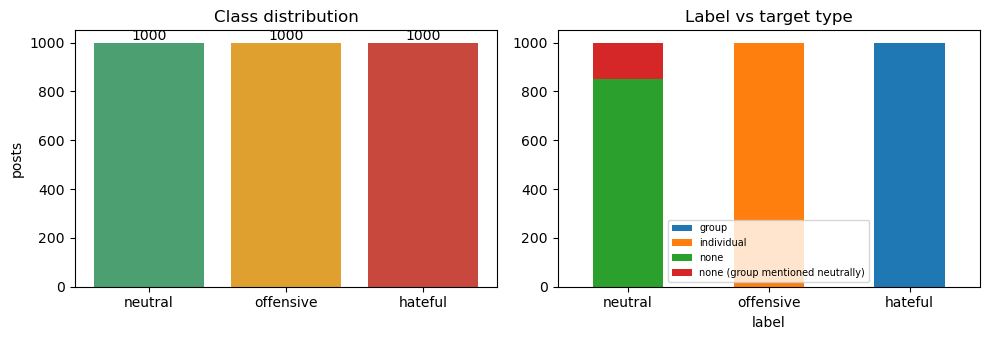

Exact duplicate texts      : 0
Near-duplicate texts       : 274
Near-duplicates w/ conflicting labels: 0


In [6]:
# 2.1 Class balance and (if present) target type
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
counts = df_raw.label.value_counts().reindex(LABELS)
ax[0].bar(counts.index, counts.values, color=["#4c9f70", "#e0a030", "#c9483d"])
ax[0].set_title("Class distribution"); ax[0].set_ylabel("posts")
for i, v in enumerate(counts.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
if "target_type" in df_raw.columns:
    ct = pd.crosstab(df_raw.label, df_raw.target_type).reindex(LABELS)
    ct.plot(kind="bar", stacked=True, ax=ax[1], rot=0); ax[1].set_title("Label vs target type")
    ax[1].legend(fontsize=7)
else:
    ax[1].axis("off")
plt.tight_layout(); plt.show()

# 2.2 Data quality
df_raw["clean"] = df_raw.text.map(clean_text); df_raw["key"] = df_raw.clean.map(dup_key)
print("Exact duplicate texts      :", df_raw.text.duplicated().sum())
print("Near-duplicate texts       :", df_raw.key.duplicated().sum())
conflict = df_raw.groupby("key").label.nunique()
print("Near-duplicates w/ conflicting labels:", int((conflict > 1).sum()))

,n_words,n_chars,devanagari_share,has_english_word,has_emoji,has_hashtag,has_mention
label,,,,,,,
neutral,11.648,64.711,0.693,0.898,0.676,0.229,0.0
offensive,11.268,60.162,0.717,0.905,0.624,0.110,0.0
hateful,13.258,75.834,0.761,0.867,0.648,0.108,0.0


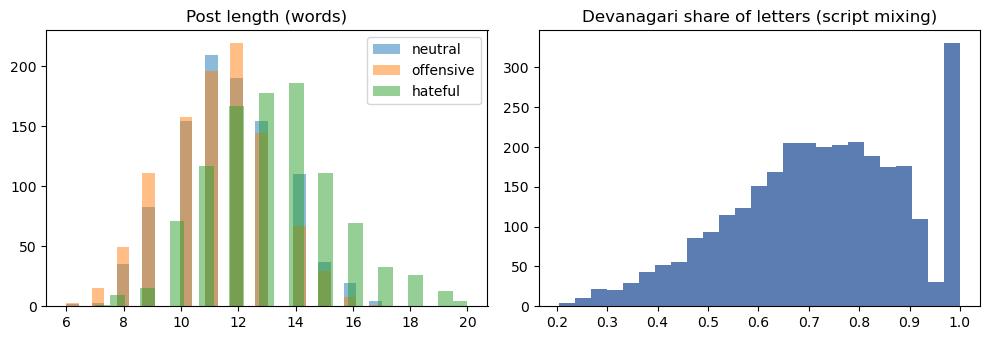

Max length (words): 20 | 95th percentile: 16


In [7]:
# 2.3 Length, script mix, emoji/hashtag usage per class
DEV = re.compile(r"[\u0900-\u097F]"); LAT = re.compile(r"[A-Za-z]")
EMOJI = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
def script_stats(t):
    d, l = len(DEV.findall(t)), len(LAT.findall(t))
    return pd.Series({"devanagari_share": d / max(d + l, 1), "has_english_word": int(l > 0)})

eda = df_raw.copy()
eda["n_words"] = eda.text.str.split().str.len()
eda["n_chars"] = eda.text.str.len()
eda = pd.concat([eda, eda.text.apply(script_stats)], axis=1)
eda["has_emoji"]   = eda.text.str.contains(EMOJI).astype(int)
eda["has_hashtag"] = eda.text.str.contains(r"#\w+").astype(int)
eda["has_mention"] = eda.text.str.contains(r"@\w+").astype(int)

summary = eda.groupby("label")[["n_words", "n_chars", "devanagari_share", "has_english_word",
                                "has_emoji", "has_hashtag", "has_mention"]].mean().reindex(LABELS).round(3)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for l in LABELS: ax[0].hist(eda[eda.label == l].n_words, bins=25, alpha=0.5, label=l)
ax[0].set_title("Post length (words)"); ax[0].legend()
ax[1].hist(eda.devanagari_share, bins=25, color="#5b7db1"); ax[1].set_title("Devanagari share of letters (script mixing)")
plt.tight_layout(); plt.show()
print("Max length (words):", eda.n_words.max(), "| 95th percentile:", int(eda.n_words.quantile(.95)))

In [8]:
# 2.4 Most frequent tokens per class (shown as tables, because plots may not render Devanagari)
TOK = re.compile(r"[\u0900-\u097F]+|[A-Za-z]+")
tok_counts = {l: Counter(w.lower() for t in df_raw[df_raw.label == l].clean for w in TOK.findall(t)) for l in LABELS}
top = pd.DataFrame({l: [f"{w} ({c})" for w, c in tok_counts[l].most_common(15)] for l in LABELS})
display(top)

# sample posts per class
for l in LABELS:
    print(f"\n--- {l} ---")
    for t in df_raw[df_raw.label == l].text.sample(3, random_state=SEED): print("  ", t)

,neutral,offensive,hateful
0,आहे (579),काय (242),आहेत (298)
1,मध्ये (314),आहे (240),सगळे (278)
2,update (281),आहेस (230),त्यांना (272)
3,करा (257),सगळे (226),म्हणजे (262)
4,आज (237),नाही (223),आपल्या (234)
5,काय (222),यार (202),आहे (233)
6,ला (217),तू (189),लोक (210)
7,मस्त (203),up (177),या (197)
8,खूप (196),तुझी (174),नको (188)
9,छान (157),बकवास (167),नाही (186)



--- neutral ---
   Update: DBMS चा assignment submit केला, आता झोपतो तुम्ही काय करता? 😊
   UPDATE: EXAM RESULT साठी औरंगाबाद मध्ये FULL तयारी चालू आहे #PUNE 😊
   Update: माझ्या आईच्या हातचं भाकरी सारखं कुठेच मिळत नाही मस्त वाटलं. 😂

--- offensive ---
   सगळे ऐका, dont talk to me loser, तुझी लायकी नाही सगळे सहमत होतील. 🤬
   Tweet करतोय: हा referee एक नंबर गाढव आहे, match विकली 😤
   सगळे ऐका, काय फालतू बकवास आहे हे, कुठल्या फेकुचंद ने बनवला? बस. 🤬

--- hateful ---
   उत्तर भारतीय लोकांना या शहरातून बाहेर काढा, हे लोक फक्त problem आहेत सगळे सहमत होतील.
   भाऊ, ब्राह्मण सोबत राहणे impossible आहे, हे लोक माणुसकीला लाजवतात wake up people. 😤
   outsiders are the reason for everything wrong, त्यांना इथे येण्याची परवानगीच द्यायला नको wake up people. 😡


## 3. Preprocessing & train / validation / test split

In [9]:
df = df_raw.drop_duplicates("key").reset_index(drop=True)
print(f"Removed {len(df_raw) - len(df)} near-duplicates -> {len(df)} posts")

train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df  = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label, random_state=SEED)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{n:5s} {len(d):5d}  ", d.label.value_counts().reindex(LABELS).to_dict())
    d[["id"]].to_csv(f"{OUT_DIR}/split_{n}_ids.csv", index=False)

roman = None
if ROMAN_PATH and os.path.exists(ROMAN_PATH):
    roman = load_csv(ROMAN_PATH); roman["clean"] = roman.text.map(clean_text)
    print("Cross-script test set:", len(roman))

results, cross_results, preds, cross_preds = {}, {}, {}, {}

Removed 274 near-duplicates -> 2726 posts
train  1908   {'neutral': 547, 'offensive': 678, 'hateful': 683}
val     409   {'neutral': 117, 'offensive': 146, 'hateful': 146}
test    409   {'neutral': 117, 'offensive': 145, 'hateful': 147}
Cross-script test set: 3000


## 4. Baseline model: TF-IDF (character n-grams) + Logistic Regression

In [10]:
t0 = time.time()
baseline = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2),
    LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline.fit(train_df.clean, train_df.label)
base_train_time = time.time() - t0

print("Validation macro-F1:", round(f1_score(val_df.label, baseline.predict(val_df.clean), average="macro"), 4))
t0 = time.time(); preds["Baseline (TF-IDF + LogReg)"] = baseline.predict(test_df.clean)
ms = (time.time() - t0) / len(test_df) * 1000
n_feat = len(baseline.named_steps["tfidfvectorizer"].vocabulary_) * len(LABELS)
results["Baseline (TF-IDF + LogReg)"] = evaluate("Baseline (TF-IDF + LogReg)", test_df.label,
                                                  preds["Baseline (TF-IDF + LogReg)"], base_train_time, ms, n_feat)
if roman is not None:
    cross_preds["Baseline (TF-IDF + LogReg)"] = baseline.predict(roman.clean)
print(f"Baseline trained in {base_train_time:.1f}s")

Validation macro-F1: 1.0
Baseline trained in 0.8s


## 5. Advanced model: fine-tuned MuRIL (transformer)

In [11]:
if RUN_TRANSFORMER:
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)

    class TextDS(Dataset):
        def __init__(self, texts, labels=None):
            self.enc = tok(list(texts), truncation=True, max_length=MAX_LEN)
            self.labels = None if labels is None else [label2id[l] for l in labels]
        def __len__(self): return len(self.enc["input_ids"])
        def __getitem__(self, i):
            item = {k: v[i] for k, v in self.enc.items()}
            if self.labels is not None: item["labels"] = self.labels[i]
            return item

    def compute_metrics(p):
        pr = p.predictions.argmax(-1)
        return {"macro_f1": f1_score(p.label_ids, pr, average="macro"), "accuracy": accuracy_score(p.label_ids, pr)}

    train_ds, val_ds = TextDS(train_df.clean, train_df.label), TextDS(val_df.clean, val_df.label)
    test_ds = TextDS(test_df.clean, test_df.label)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id)

    eval_key = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"
    args = TrainingArguments(
        output_dir=f"{OUT_DIR}/muril_checkpoints", num_train_epochs=EPOCHS, learning_rate=3e-5,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=64, weight_decay=0.01, warmup_ratio=0.1,
        save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_f1",
        logging_steps=20, seed=SEED, report_to="none", fp16=HAS_GPU, **{eval_key: "epoch"})

    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    t0 = time.time(); trainer.train(); bert_train_time = time.time() - t0
    print(f"MuRIL trained in {bert_train_time/60:.1f} min")

    def trainer_predict(ds):
        return np.array([id2label[i] for i in trainer.predict(ds).predictions.argmax(-1)])

    name = "MuRIL (fine-tuned)"
    t0 = time.time(); preds[name] = trainer_predict(test_ds); ms = (time.time() - t0) / len(test_df) * 1000
    results[name] = evaluate(name, test_df.label, preds[name], bert_train_time, ms,
                             sum(p.numel() for p in model.parameters()))
    if roman is not None: cross_preds[name] = trainer_predict(TextDS(roman.clean, roman.label))
else:
    print("RUN_TRANSFORMER=False: skipping the advanced model.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expe

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.415343,0.314505,1.000000,1.000000
2,0.090417,0.074552,1.000000,1.000000
3,0.055426,0.050322,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

MuRIL trained in 20.4 min


## 6. Evaluation & comparison (same held-out test set for both models)


===== Baseline (TF-IDF + LogReg) =====
              precision    recall  f1-score   support

     neutral      1.000     1.000     1.000       117
   offensive      1.000     1.000     1.000       145
     hateful      1.000     1.000     1.000       147

    accuracy                          1.000       409
   macro avg      1.000     1.000     1.000       409
weighted avg      1.000     1.000     1.000       409


===== MuRIL (fine-tuned) =====
              precision    recall  f1-score   support

     neutral      1.000     1.000     1.000       117
   offensive      1.000     1.000     1.000       145
     hateful      1.000     1.000     1.000       147

    accuracy                          1.000       409
   macro avg      1.000     1.000     1.000       409
weighted avg      1.000     1.000     1.000       409



,accuracy,macro_F1,weighted_F1,F1_neutral,F1_offensive,F1_hateful,train_time_s,ms_per_post,params
model,,,,,,,,,
Baseline (TF-IDF + LogReg),1.0,1.0,1.0,1.0,1.0,1.0,0.8188,0.2051,16899
MuRIL (fine-tuned),1.0,1.0,1.0,1.0,1.0,1.0,1222.1740,21.2437,237558531


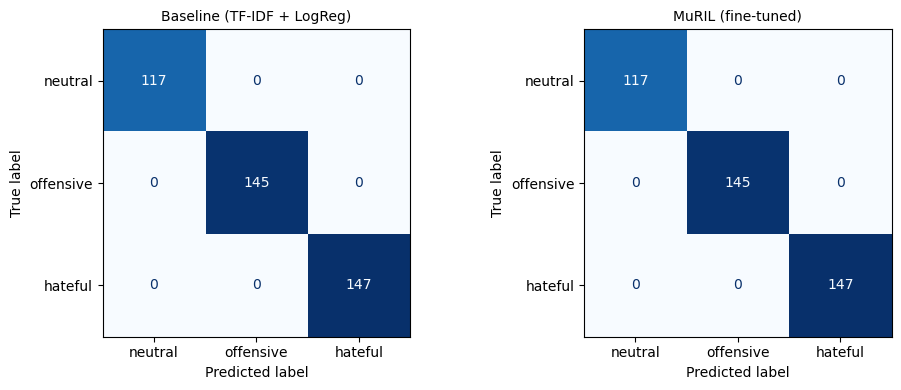

In [12]:
for name, p in preds.items():
    print(f"\n===== {name} =====")
    print(classification_report(test_df.label, p, labels=LABELS, digits=3))

comparison = pd.DataFrame(results.values()).set_index("model").round(4)
display(comparison)

fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 4), squeeze=False)
for ax, (name, p) in zip(axes[0], preds.items()):
    ConfusionMatrixDisplay.from_predictions(test_df.label, p, labels=LABELS, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

In [13]:
# Is the difference real? Bootstrap 95% confidence intervals for macro-F1
rng = np.random.default_rng(SEED); y = test_df.label.values
def bootstrap(pred_dict, n=1000):
    names = list(pred_dict); store = {k: [] for k in names}
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        for k in names: store[k].append(f1_score(y[idx], pred_dict[k][idx], average="macro"))
    return store

boot = bootstrap({k: np.array(v) for k, v in preds.items()})
for k, v in boot.items(): print(f"{k:30s} macro-F1 95% CI: {np.percentile(v, 2.5):.4f} - {np.percentile(v, 97.5):.4f}")
if len(boot) == 2:
    a, b = list(boot.values()); d = np.array(b) - np.array(a)
    print(f"\nDifference (advanced - baseline) 95% CI: {np.percentile(d, 2.5):.4f} to {np.percentile(d, 97.5):.4f}",
          "-> not significant if it includes 0")

Baseline (TF-IDF + LogReg)     macro-F1 95% CI: 1.0000 - 1.0000
MuRIL (fine-tuned)             macro-F1 95% CI: 1.0000 - 1.0000

Difference (advanced - baseline) 95% CI: 0.0000 to 0.0000 -> not significant if it includes 0


## 7. Robustness test: train on Devanagari, test on Roman-script Marathi-English
The in-distribution test can be too easy. This tests how the models handle a script/spelling shift (models were never trained on this file).

,accuracy,macro_F1,weighted_F1,F1_neutral,F1_offensive,F1_hateful
model,,,,,,
Baseline (TF-IDF + LogReg),0.8613,0.8586,0.8586,0.9048,0.8507,0.8203
MuRIL (fine-tuned),0.9187,0.9185,0.9185,0.8868,0.9017,0.9671


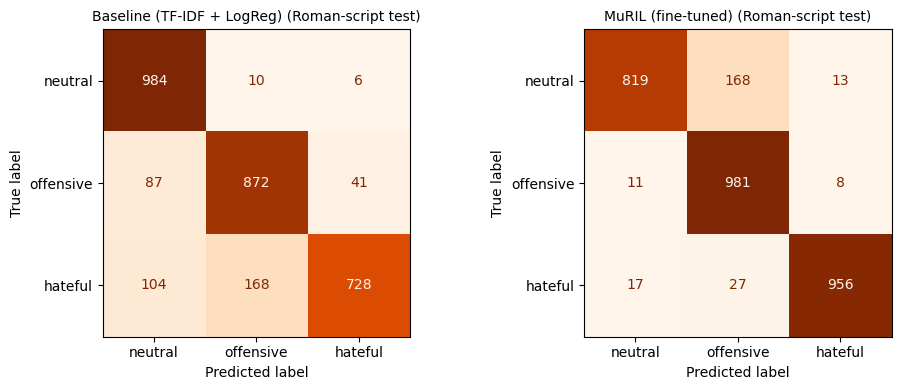

In [14]:
if roman is not None:
    rows = [evaluate(n, roman.label, p) for n, p in cross_preds.items()]
    display(pd.DataFrame(rows).set_index("model")[["accuracy", "macro_F1", "weighted_F1"] + [f"F1_{l}" for l in LABELS]].round(4))
    fig, axes = plt.subplots(1, len(cross_preds), figsize=(5 * len(cross_preds), 4), squeeze=False)
    for ax, (n, p) in zip(axes[0], cross_preds.items()):
        ConfusionMatrixDisplay.from_predictions(roman.label, p, labels=LABELS, cmap="Oranges", ax=ax, colorbar=False)
        ax.set_title(f"{n} (Roman-script test)", fontsize=10)
    plt.tight_layout(); plt.show()
else:
    print("No Roman-script file found; skipping the cross-script test.")

## 8. Error analysis

In [15]:
best = max(results, key=lambda k: results[k]["macro_F1"])
print("Best in-distribution model:", best)
errs = test_df.assign(pred=preds[best]); errs = errs[errs.label != errs.pred]
print(f"In-distribution errors: {len(errs)} / {len(test_df)}")
if len(errs): display(errs[["text", "label", "pred"] + (["target_type"] if "target_type" in errs else [])].head(30))

if roman is not None:
    last = list(cross_preds)[-1]
    ce = roman.assign(pred=cross_preds[last]); ce = ce[ce.label != ce.pred]
    print(f"\nCross-script errors for '{last}': {len(ce)} / {len(roman)}")
    display(ce.groupby(["label", "pred"]).size().rename("count").to_frame())
    if "target_type" in ce: display(ce.groupby("target_type").size().rename("errors").to_frame())
    display(ce[["text", "label", "pred"]].head(30))

# Tag a sample of errors manually in your report by cause: transliteration/spelling variation,
# English-only sentence, mid-sentence code-switching, sarcasm/implicit hate, group mentioned neutrally, label noise.

Best in-distribution model: Baseline (TF-IDF + LogReg)
In-distribution errors: 0 / 409

Cross-script errors for 'MuRIL (fine-tuned)': 244 / 3000


count
label     pred            
hateful   neutral       17
          offensive     27
neutral   hateful       13
          offensive    168
offensive hateful        8
          neutral       11

,errors
target_type,
group,44
individual,19
none,115
none (group mentioned neutrally),66


,text,label,pred
1,"MEETING RESCHEDULE ZALI AAHE, AATA UDYA 11 VAJTA TAG KARA KUNALA TARI. 🔥",neutral,offensive
3,"Gujaratis baddal ek chaan documentary pahili, khup shikayla milala Tumhi kay karta? 👍",neutral,offensive
4,"Aaj amhi migrants chya saunskrutik karyakramala gelo hoto, khup chaan anubhav Tag kara kunala tari. ❤️",neutral,offensive
9,Update: Majhya aaichya hatche batata vada sarkhe kuthech nahi milat Kay mhanta? 👍,neutral,offensive
11,"Pavsala suruvat zali Satara madhe, chai ani bhaji chi vel Kay mhanta? 🔥",neutral,offensive
15,"Bengalis baddal ek chaan documentary pahili, khup shikayla milala 😂",neutral,offensive
19,"ARRE YAAR, BIHARIS LA IKDE RAHAYCHA ADHIKAR NAHI, SIMPLE SHARE KARA. 👎",hateful,neutral
45,"MI TULA SANGTO BEWAKUF, COMMENT KARNYAADHI VICHAR KAR FACT AAHE. 👎",offensive,neutral
64,"Ratnagiri madhla tapman aaj khup kami aahe, sweater ghya Kay mhanta?",neutral,offensive
68,"Aaj amhi Sikhs chya saunskrutik karyakramala gelo hoto, khup chaan anubhav #Maharashtra 👍",neutral,offensive


## 9. Save models & inference helper

In [16]:
joblib.dump(baseline, f"{OUT_DIR}/baseline_tfidf_logreg.joblib")
comparison.to_csv(f"{OUT_DIR}/model_comparison.csv")
if RUN_TRANSFORMER:
    trainer.save_model(f"{OUT_DIR}/muril_hate_marathi"); tok.save_pretrained(f"{OUT_DIR}/muril_hate_marathi")

def predict(texts, model="baseline"):
    """Classify one or more posts. model = 'baseline' or 'muril'."""
    if isinstance(texts, str): texts = [texts]
    cleaned = [clean_text(t) for t in texts]
    if model == "baseline":
        return list(baseline.predict(cleaned))
    enc = tok(cleaned, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(trainer.model.device)
    with torch.no_grad(): logits = trainer.model(**enc).logits
    return [id2label[i] for i in logits.argmax(-1).tolist()]

print(predict(["उद्या college ला सुट्टी आहे, मस्त plan करूया"], "baseline"))
if RUN_TRANSFORMER: print(predict(["उद्या college ला सुट्टी आहे, मस्त plan करूया"], "muril"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['neutral']
['neutral']


In [17]:
## 10. Try it: analyse your own post
Run the cell below, paste a post (one line) into the box that appears, and press Enter. Both models classify it and show their confidence for each class. Press Enter on an empty line to stop.

SyntaxError: invalid syntax (3616778798.py, line 2)

In [ ]:
def _probs_baseline(cleaned):
    p = baseline.predict_proba([cleaned])[0]
    d = dict(zip(baseline.classes_, p))
    return [d.get(l, 0.0) for l in LABELS]

def _probs_muril(cleaned):
    enc = tok([cleaned], truncation=True, max_length=MAX_LEN, return_tensors="pt").to(trainer.model.device)
    trainer.model.eval()
    with torch.no_grad(): logits = trainer.model(**enc).logits[0]
    p = torch.softmax(logits, -1).cpu().numpy()
    return [float(p[label2id[l]]) for l in LABELS]

def analyze_post(text):
    """Clean a post, run every trained model on it, and print predictions with confidence."""
    cleaned = clean_text(text)
    no_tags = re.sub(r"<[A-Z]+>", "", cleaned)          # ignore <USER>, <URL> placeholders
    dev, lat = len(DEV.findall(no_tags)), len(LAT.findall(no_tags))
    print("-" * 70)
    print("Cleaned text :", cleaned)
    print(f"Script mix   : {dev} Devanagari letters, {lat} Latin letters ->",
          "code-mixed" if dev and lat else ("Devanagari only" if dev else "Latin/Roman only"))
    table = {"Baseline (TF-IDF + LogReg)": _probs_baseline(cleaned)}
    if RUN_TRANSFORMER: table["MuRIL (fine-tuned)"] = _probs_muril(cleaned)
    probs = pd.DataFrame(table, index=LABELS)
    display((probs * 100).round(1).astype(str) + " %")
    verdicts = {m: LABELS[int(np.argmax(probs[m]))] for m in probs}
    for m, v in verdicts.items():
        print(f"{m:28s} -> {v.upper():10s} (confidence {probs[m].max()*100:.1f}%)")
    if len(set(verdicts.values())) > 1: print("Note: the models disagree on this post.")
    return probs

while True:
    post = input("Paste a post (empty line to stop): ")
    if not post.strip(): break
    analyze_post(post)

Paste a post (empty line to stop):  सस्नेह जय महाराष्ट्र,  भारतीय जनता पक्ष आणि त्यांनी पोसलेला विषारी सोशल मीडिया हा सध्या मुंबई, महाराष्ट्र येथे छठ पूजा हा मुद्दा वापरून कसा संघर्ष निर्माण करता येईल यासाठी आटोकाट प्रयत्न करतोय.  त्यासाठी सोशल मीडियावर या पूजेच्या, त्यातून सुरु असलेल्या सांस्कृतिक आक्रमणांच्या रिल्स सोशल मीडियावर टाकत आहेत. हे पुरेसं नाही म्हणून मुंबईतील काही रेल्वे स्थानकांवर भोजपुरी गाणी वाजवून पाहिली, जी महाराष्ट्र नवनिर्माण सेनेने बंद पाडली तो भाग वेगळा. पण या सगळ्यातून अजून भारतीय जनता पक्षाला जो संघर्ष अपेक्षित आहे तो उभा राहत नाहीये ही त्यांना खंत आहे. आणि हा सगळा आटापिटा सुरु आहे आगामी उत्तर प्रदेश निवडणुकांसाठी.  भारतीय जनता पक्षाचा जो काही एक थिंक टॅंक आहे त्याची बौद्धिक क्षमता कमकुवत झाली आहे असं दिसतंय. कारण निवडणुका जिंकण्यासाठी त्यांनी वर्षानुवर्षे वापरलेला फोडा आणि राज्य करा हा फॉर्म्युला आता काम करणार नाही. लोकसभेच्या निवडणुका आल्या की हिंदू मुस्लिम वाद पेटवायचा, मैदानांमध्ये, बागांमध्ये मुस्लिम बुरखा घातलेल्या स्त्रिया फिरवून बघा बघा आता हे आपल्या मैद

----------------------------------------------------------------------
Cleaned text : सस्नेह जय महाराष्ट्र, भारतीय जनता पक्ष आणि त्यांनी पोसलेला विषारी सोशल मीडिया हा सध्या मुंबई, महाराष्ट्र येथे छठ पूजा हा मुद्दा वापरून कसा संघर्ष निर्माण करता येईल यासाठी आटोकाट प्रयत्न करतोय. त्यासाठी सोशल मीडियावर या पूजेच्या, त्यातून सुरु असलेल्या सांस्कृतिक आक्रमणांच्या रिल्स सोशल मीडियावर टाकत आहेत. हे पुरेसं नाही म्हणून मुंबईतील काही रेल्वे स्थानकांवर भोजपुरी गाणी वाजवून पाहिली, जी महाराष्ट्र नवनिर्माण सेनेने बंद पाडली तो भाग वेगळा. पण या सगळ्यातून अजून भारतीय जनता पक्षाला जो संघर्ष अपेक्षित आहे तो उभा राहत नाहीये ही त्यांना खंत आहे. आणि हा सगळा आटापिटा सुरु आहे आगामी उत्तर प्रदेश निवडणुकांसाठी. भारतीय जनता पक्षाचा जो काही एक थिंक टॅंक आहे त्याची बौद्धिक क्षमता कमकुवत झाली आहे असं दिसतंय. कारण निवडणुका जिंकण्यासाठी त्यांनी वर्षानुवर्षे वापरलेला फोडा आणि राज्य करा हा फॉर्म्युला आता काम करणार नाही. लोकसभेच्या निवडणुका आल्या की हिंदू मुस्लिम वाद पेटवायचा, मैदानांमध्ये, बागांमध्ये मुस्लिम बुरखा घातल

,Baseline (TF-IDF + LogReg),MuRIL (fine-tuned)
neutral,18.0 %,9.7 %
offensive,2.7 %,10.7 %
hateful,79.2 %,79.5 %


Baseline (TF-IDF + LogReg)   -> HATEFUL    (confidence 79.2%)
MuRIL (fine-tuned)           -> HATEFUL    (confidence 79.5%)


## 10. Notes for your report
- **Dataset:** state clearly where the data came from. If it is synthetic or generated, say so. If you use HASOC, cite the FIRE overview paper.
- **Ethics:** personal information is masked (`<USER>`, `<URL>`, `<EMAIL>`, `<PHONE>`); do not commit raw datasets to GitHub.
- **Comparison:** report macro-F1 as the main metric, plus per-class F1, the confusion matrices, bootstrap confidence intervals, and training/inference cost.
- **Caveat:** if the baseline already scores ~1.00 in-distribution, the dataset is too easy to separate the models; rely on the cross-script test and on a harder real dataset (e.g. HASOC).